# Seeing where electric current enters the soil

## 1. Imaging question

Electrode potential differences contain a blurred signature of where current enters a conductive soil medium. We recover a17×17 spatial map of dimensionless release fractions from204transfer resistances. These are **existing original-author simulated observations**, not laboratory measurements. The known-medium unit-current matrix is legitimate calibration independent of the unknown release. This source inversion is distinct from inferring conductivity. No actual spatial source truth is available in the bound files; the standard-method reference is labeled accordingly.

In [1]:
from pathlib import Path
import sys,time,json,os,platform
import numpy as np,scipy
import matplotlib,matplotlib.pyplot as plt
root=Path.cwd()
if root.name=='notebooks':root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data
from src.solvers import reconstruct
from src import visualization as viz
print('ACTUAL_KERNEL_ENVIRONMENT',json.dumps({'executable':sys.executable,'python':sys.version,'os':platform.platform(),'numpy':np.__version__,'numpy_file':np.__file__,'scipy':scipy.__version__,'matplotlib':matplotlib.__version__,'backend':matplotlib.get_backend(),'threads':{k:os.environ.get(k) for k in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']}}))
d=load_data(root/'data/raw_data.npz')
with np.load(root/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as f:author=f['reconstruction'][0]
sources={}
def show(name,result):
    fig,nums=result;sources.update({name+'_'+k:v for k,v in nums.items()});plt.show()
print({k:v.shape for k,v in d.items()})

ACTUAL_KERNEL_ENVIRONMENT {"executable": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe", "python": "3.11.11 (main, Mar 17 2025, 21:01:29) [MSC v.1943 64 bit (AMD64)]", "os": "Windows-10-10.0.26200-SP0", "numpy": "2.4.6", "numpy_file": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Lib\\site-packages\\numpy\\__init__.py", "scipy": "1.17.1", "matplotlib": "3.11.1", "backend": "module://matplotlib_inline.backend_inline", "threads": {"OMP_NUM_THREADS": "1", "OPENBLAS_NUM_THREADS": "1", "MKL_NUM_THREADS": "1"}}
{'observations': (204,), 'green_matrix': (204, 289), 'source_coordinates': (289, 2)}


## 2. Observations and independent calibration

The original simulated transfer resistances retain sign and order. Each matrix column represents a unit-source response in the prescribed conductive medium, including the reference electrode and boundary convention. No current-source solution is used to estimate that matrix. Coordinates are metres, with.03mspacing and xslow/yfast storage. Because electrode fields are broad and there are more source nodes than observations, direct inversion is ambiguous. All204observations remain in the fit.

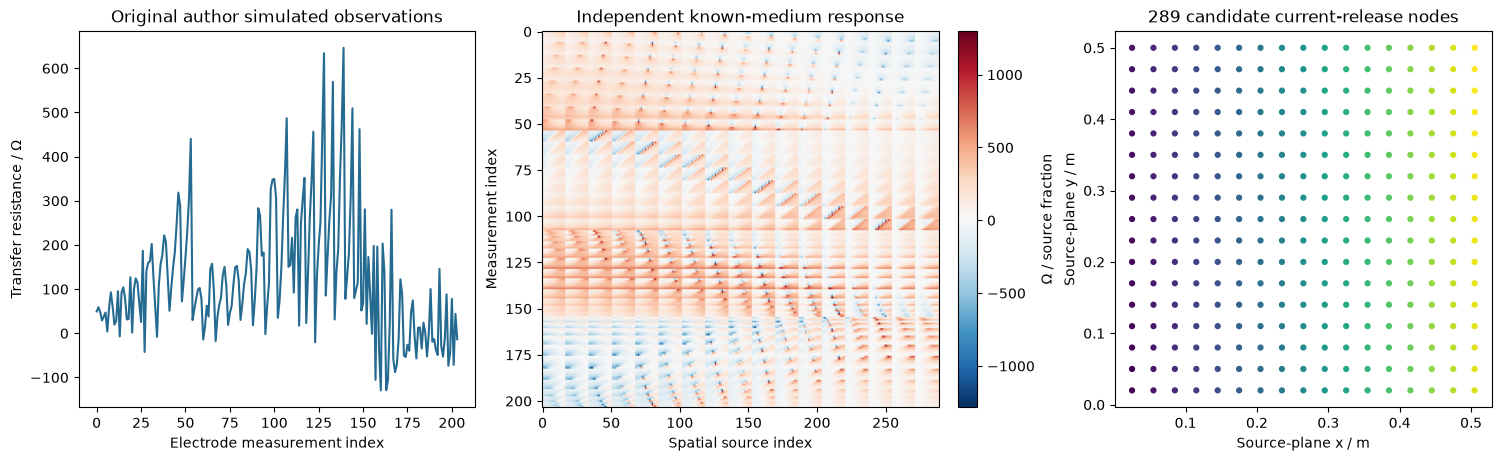

In [2]:
show('acquisition',viz.acquisition(d))

## 3. Explicit inverse mathematics and a source boundary convention

For transfer resistance d, known response G and source fractions q, the forward model is d=Gq+e. Minimize

$$\frac12\|W(Gq-d)\|_2^2+\frac12w_c^2(\mathbf1^Tq-1)^2+\frac12w_r^2\|Rq\|_2^2,\qquad0\le q\le1.$$

W has diagonal min(1,1/sqrt(abs(d))) in the original numerical-ohm weighting convention. The conservation weight is1000and roughness weight1. R is an explicit nearest-neighbor incidence matrix. The original selected source loop nests one direction's edges inside the other direction's boundary condition; this omits16edges on the final yboundary. We preserve the exact connected528-edge graph and identify its anisotropic boundary treatment. Its Laplacian is positive semidefinite with a single constant null mode. No claim of complete isotropic smoothing is made.

A general bounded linear least-squares optimizer solves the explicitly assembled local system. The original default conservation weight100000is ill-conditioned for this dataset and stops with a large KKT residual. Original code supports the chosen adjustable weight1000; the independent oracle established its improved optimality before local extraction. Conservation remains a finite penalty; no post-fit normalization changes the original solution.

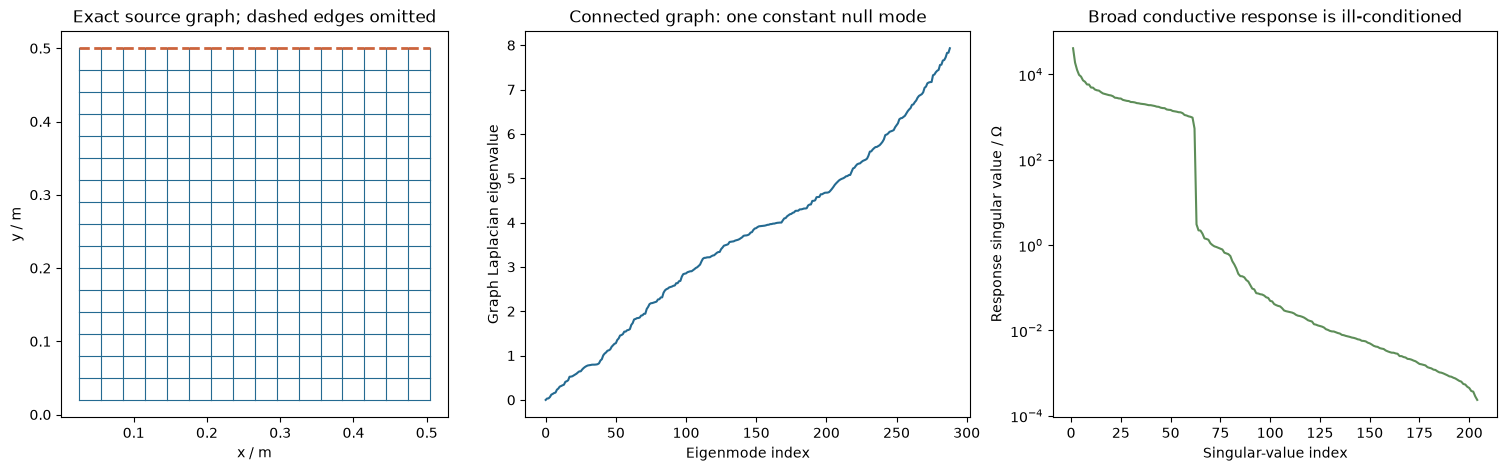

Fresh complete reconstruction seconds 0.1391552999994019 sum 1.0006324393820427 optimality 1.1887452711309775e-08


In [3]:
show('graph',viz.graph(d))
start=time.perf_counter();maps,pred,result=reconstruct(d);runtime=time.perf_counter()-start
print('Fresh complete reconstruction seconds',runtime,'sum',maps.sum(),'optimality',result.optimality)

## 4. Independent reproduction and residual evidence

Original arrays below were obtained by executing the unmodified author preprocessing, graph assembly, weighting and bounded solver on exactly the bound observations. Fresh arrays are computed above. The original file named truemodel has the204observation values rather than a289node source map, so it is not a spatial truth and is not used as one. Agreement is assessed at absolute source-fraction scale without shift, gain or normalization. The standalone Judge scores cosine NCC and dynamic-range NRMSE.

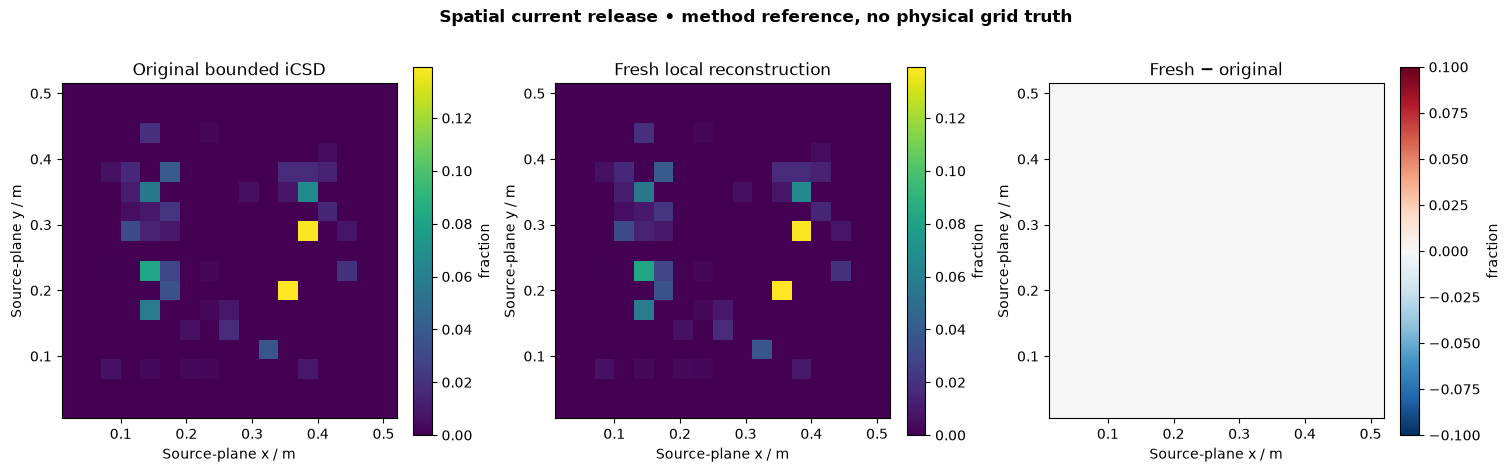

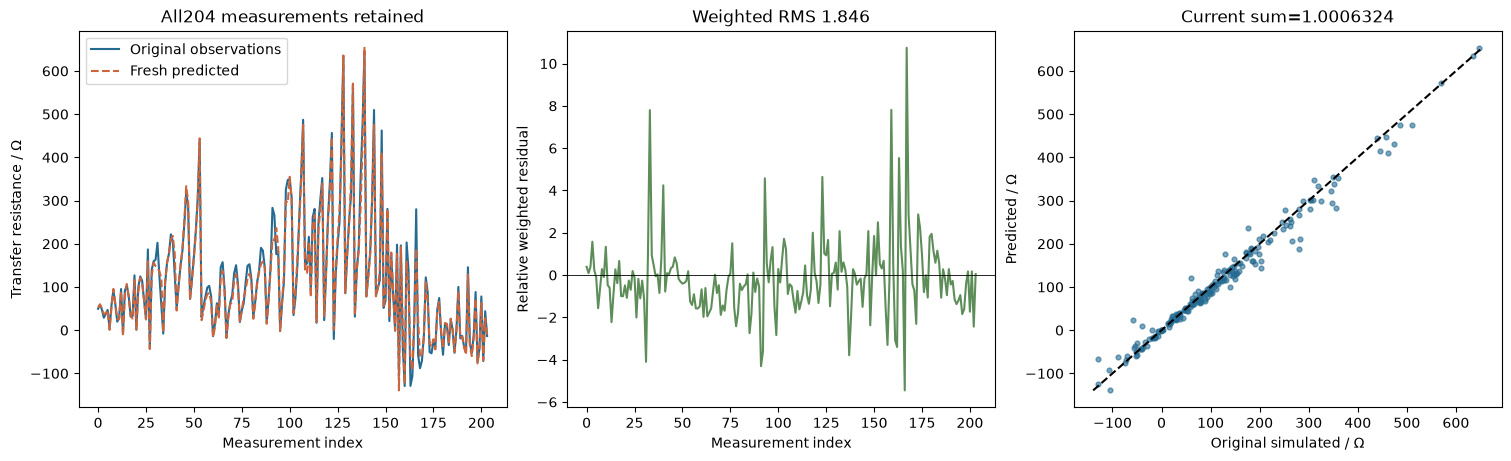

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 1.0,
    "reconstruction_nrmse": 0.0
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boundary": 0.99999
    },
    "reconstruction_nrmse": {
      "comparison": "<=",
      "boundary": 0.0001
    }
  },
  "errors": []
}


In [4]:
show('components',viz.components(maps,author))
show('residuals',viz.residuals(d,pred,maps))
from importlib.util import spec_from_file_location,module_from_spec
s=spec_from_file_location('independent_judge',root/'evaluation/judge.py');judge=module_from_spec(s);s.loader.exec_module(judge)
np.savez_compressed(root/'output/reconstruction.npz',reconstruction=maps[None]);report,code=judge.evaluate(root/'output/reconstruction.npz');assert code==0
print(json.dumps(report,indent=2))

## 5. Computed comparisons and regularization experiments

We actively solve the original default high-conservation-weight model, the selected better-conditioned original model, and a separately labeled complete-edge-graph ablation. The ablation changes a source boundary convention and is not substituted for the selected published-code method. Nine full spatial reconstructions then vary the roughness weight while keeping all actual observations and calibration fixed. Their residual, roughness and current-sum curves reveal the resolution–stability tradeoff. None of these computed alternatives is treated as truth.

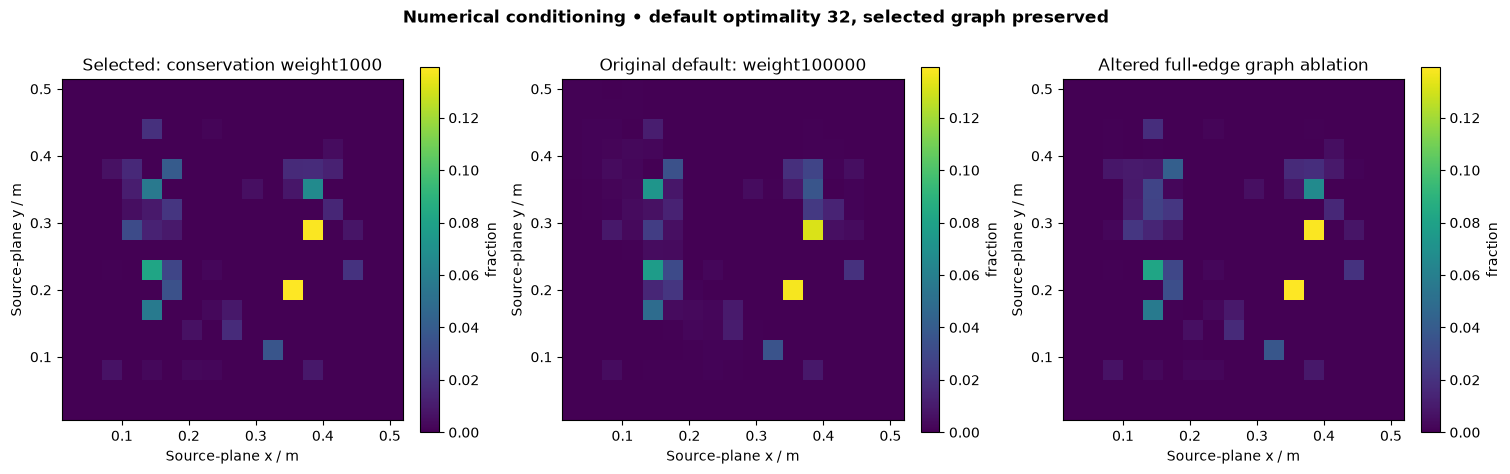

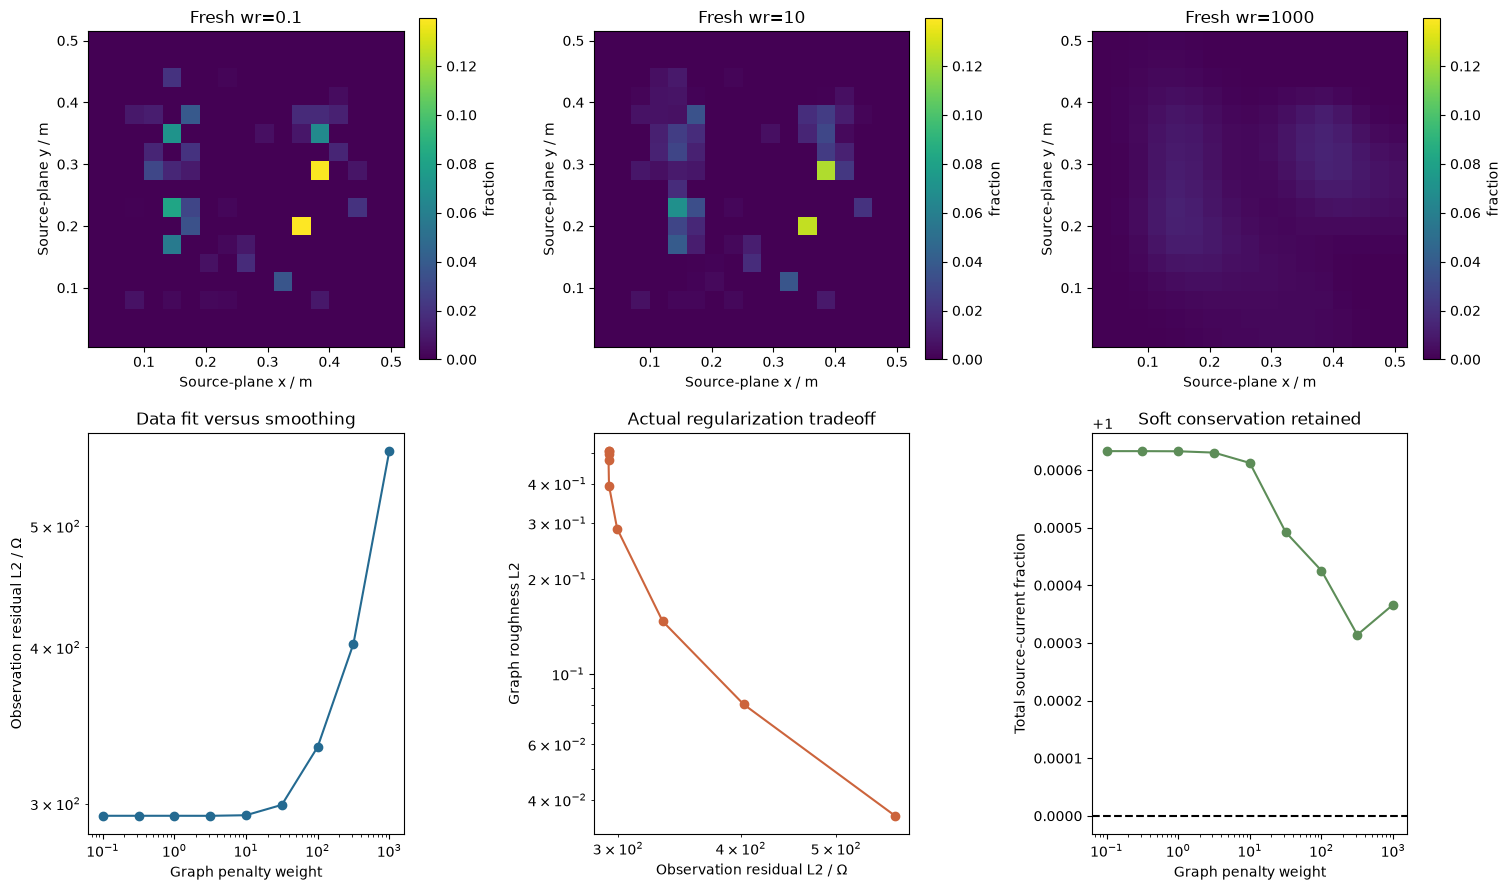

In [5]:
show('comparisons',viz.comparisons(d,maps))
show('sensitivity',viz.sensitivity(d))

## 6. Interpretation and limits

The fresh local inverse reproduces the selected original bounded source-imaging method with explicit calibrated superposition, regularization graph and conservation physics. Broad sensitivity, limited data and regularization affect localization, so the source map is conditional on the supplied medium response. This benchmark does not infer root architecture directly or establish biological truth. Signed measurement residuals, numerical optimality and the conserved source sum provide checks beyond method agreement. All displayed alternatives and sensitivity images were computed during this notebook execution.

In [6]:
print('All source inversions and diagnostics completed; numeric plot arrays',len(sources))

All source inversions and diagnostics completed; numeric plot arrays 21
